In [1]:
%pip install -q tensorflow keras pandas scikit-learn matplotlib seaborn visualkeras datasets transformers


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Module 5.1 Assignment - Transformer-based Sentiment Classification

> Submitted by Phillip Amir Esguerra

# 1. Loading IMDB Dataset

In [2]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
dataset = load_dataset("imdb",  cache_dir="./.data")

# 2. Dataset to DataFrame

In [12]:
train_dataset = dataset['train']
test_dataset = dataset['test']

In [13]:
def print_df_info(df, name="DataFrame"):
    print(f"========== {name} Sample Data ==========")
    print(df.head())
    print(f"\n========== {name} Data Info ==========")
    print(df.info())

In [14]:
train_df = pd.DataFrame(train_dataset)
print_df_info(train_df, "Train DataFrame")

========== Train DataFrame Sample Data ==========
                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0

========== Train DataFrame Data Info ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB
None


In [15]:
test_df = pd.DataFrame(test_dataset)
print_df_info(test_df, "Test DataFrame")

========== Test DataFrame Sample Data ==========
                                                text  label
0  I love sci-fi and am willing to put up with a ...      0
1  Worth the entertainment value of a rental, esp...      0
2  its a totally average film with a few semi-alr...      0
3  STAR RATING: ***** Saturday Night **** Friday ...      0
4  First off let me say, If you haven't enjoyed a...      0

========== Test DataFrame Data Info ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB
None


# 3. Exploratory Data Analysis

In [16]:
def create_eda_plot(df, name):
    figure, axes = plt.subplots(1,2, figsize=(15, 5))
    axes = axes.flatten()
    
    axes[0].set_title(f"{name} 'label' Distribution")
    sns.countplot(x="label", data=df, ax=axes[0])
    axes[0].set_xlabel("Label")
    axes[0].set_ylabel("Count")
    axes[0].grid(axis='y')
    
    df['review_length'] = df['text'].apply(len)
    axes[1].set_title(f"{name} Review Length Distribution")
    sns.histplot(df['review_length'], bins=50, kde=True, ax=axes[1])
    axes[1].set_xlabel("Review Length (characters)")
    axes[1].set_ylabel("Frequency")
    axes[1].grid(axis='y')

def create_eda(df, name):
    print(f"========== {name} EDA ==========")
    print(f"Number of samples: {len(df)}")
    print(f"Number of positive reviews: {len(df[df['label'] == 1])}")
    print(f"Number of negative reviews: {len(df[df['label'] == 0])}")
    print(f"Average review length: {df['text'].apply(len).mean()} characters")
    print(f"Average review word count: {df['text'].apply(lambda x: len(x.split())).mean()} words")
    
    create_eda_plot(df, name)

========== Train DataFrame EDA ==========
Number of samples: 25000
Number of positive reviews: 12500
Number of negative reviews: 12500
Average review length: 1325.06964 characters
Average review word count: 233.7872 words


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


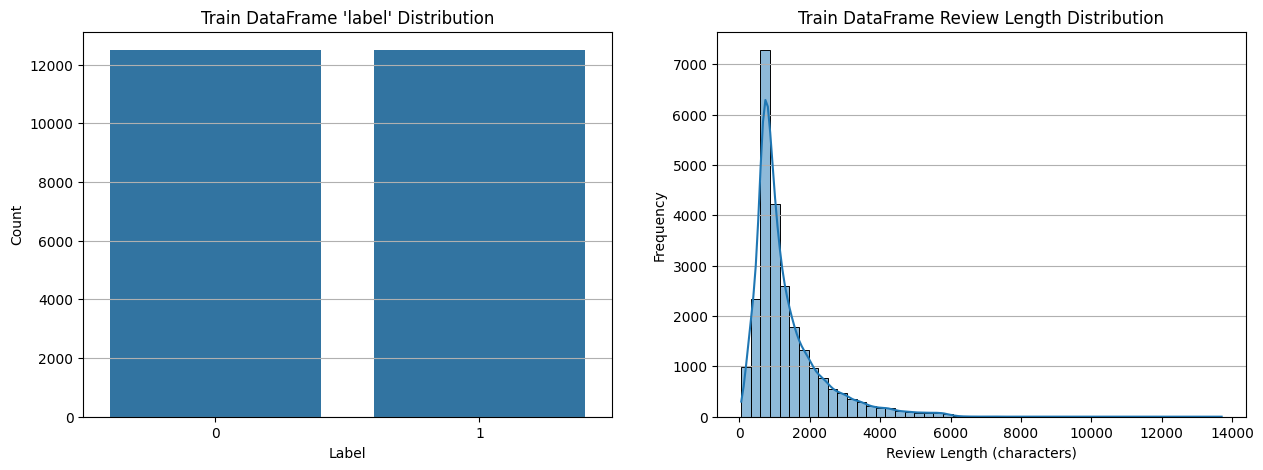

In [17]:
create_eda(train_df, "Train DataFrame")

========== Test DataFrame EDA ==========
Number of samples: 25000
Number of positive reviews: 12500
Number of negative reviews: 12500
Average review length: 1293.7924 characters
Average review word count: 228.52668 words


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


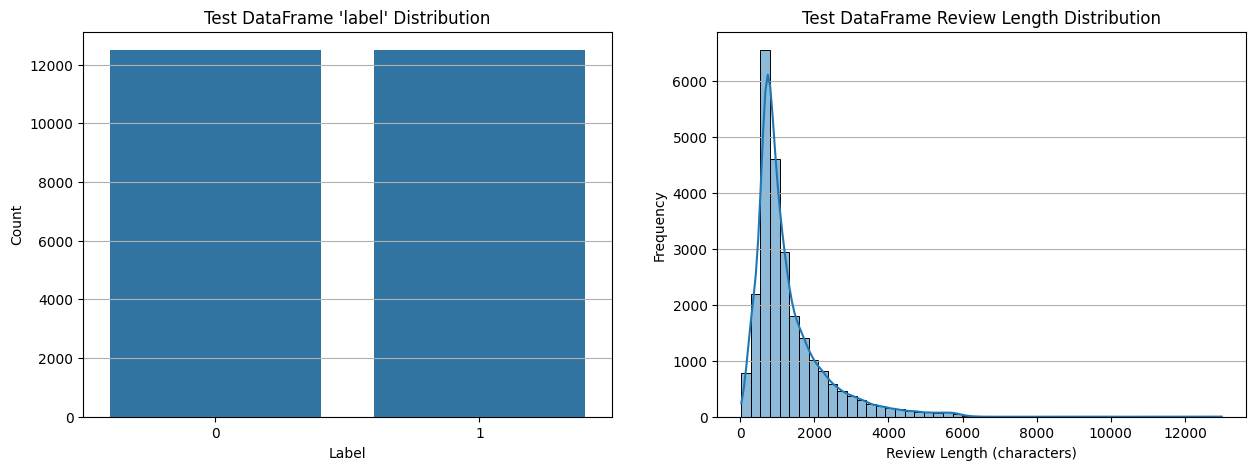

In [18]:
create_eda(test_df, "Test DataFrame")

# 4. Checking for Missing and Outlier Data

In [19]:
print("Missing values in training data:")
print(train_df.isnull().sum())

Missing values in training data:
text             0
label            0
review_length    0
dtype: int64


In [20]:
print("Missing values in test data:")
print(test_df.isnull().sum())

Missing values in test data:
text             0
label            0
review_length    0
dtype: int64


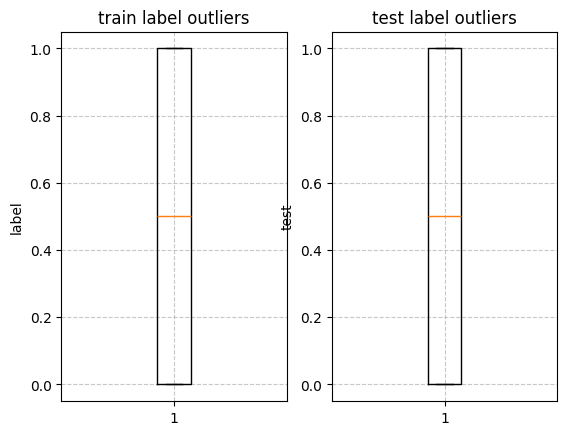

In [21]:
fig, axes = plt.subplots(1, 2)
axes = axes.flatten()

axes[0].boxplot(train_df["label"])
axes[0].set_title("train label outliers")
axes[0].set_ylabel("label")
axes[0].grid(True, linestyle="--", alpha=0.7)

axes[1].boxplot(test_df["label"])
axes[1].set_title("test label outliers")
axes[1].set_ylabel("test")
axes[1].grid(True, linestyle="--", alpha=0.7)

plt.show()

# 5-6. Text Tokenization

In [22]:
import numpy as np
from keras.src.legacy.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences

vocab_size = 2000
max_len = 256

In [24]:
tokenizer = Tokenizer(num_words=vocab_size, 
                      filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n',
                      lower=True,
                      split=" ",
                      oov_token="<OOV>")

tokenizer.fit_on_texts(train_df["text"])



In [30]:
X_training_sequences = tokenizer.texts_to_sequences(train_df["text"])
X_training_padded = pad_sequences(X_training_sequences, maxlen=max_len, truncating='post')

print(train_df["text"][0])
print(X_training_padded[0])

I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, eve

In [31]:
X_test_sequences = tokenizer.texts_to_sequences(test_df["text"])
X_test_padded = pad_sequences(X_test_sequences, maxlen=max_len, truncating='post')

print(test_df["text"][0])
print(X_test_padded[0])

I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like this, I really did, but it is to good TV sci-fi as Babylon 5 is to Star Trek (the original). Silly prosthetics, cheap cardboard sets, stilted dialogues, CG that doesn't match the background, and painfully one-dimensional characters cannot be overcome with a 'sci-fi' setting. (I'm sure there are those of you out there who think Babylon 5 is good sci-fi TV. It's not. It's clichéd and uninspiring.) While US viewers might like emotion and character development, sci-fi is a genre that does not take itself seriously (cf. Star Trek). It may treat important issues, yet not as a serious philosophy. It's really difficult to care about the characters here as they are not simply foolish, just missing a spark of life. Their actions and reactions are wooden and predictable, often painful to watch. The makers of Earth KNOW it's rubbish as they have to alway

In [29]:
y_train = train_df["label"].values
y_test = test_df["label"].values

# 7. Test Data Split

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train_split, y_val = train_test_split(
    X_training_padded, y_train, test_size=0.1, random_state=42
)

print(f"Size of training split: {X_train.shape[0]}")
print(f"Size of validation split: {X_val.shape[0]}")
print(f"Size of testing set: {X_test_padded.shape[0]}")

Size of training split: 22500
Size of validation split: 2500
Size of testing set: 25000


# 8. Basic Transformer Model

In [35]:
import keras
from keras import backend as K
from keras import layers, models, optimizers, losses, metrics

def transformer_encoder_basic(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(inputs, inputs)
    x = layers.Add()([x, inputs])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x_ff = layers.Dense(ff_dim, activation='relu')(x)
    x_ff = layers.Dense(inputs.shape[-1])(x_ff)
    x = layers.Add()([x, x_ff])
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    return x

vocab_size = min(vocab_size, len(tokenizer.word_index) + 1)
embed_dim = 64
inputs = keras.Input(shape=(max_len,), dtype='int32')
x = layers.Embedding(vocab_size, embed_dim, input_length=max_len)(inputs)
x = transformer_encoder_basic(x, head_size=32, num_heads=2, ff_dim=128, dropout=0.1)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
basic_model = keras.Model(inputs, outputs, name='basic_transformer')

basic_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy', keras.metrics.AUC(name='auc')])
print(basic_model.summary())

/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "basic_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 256, 64)   │    128,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 256, 64)   │     16,640 │ embedding_1[0][0… │
│ (MultiHeadAttentio… │                   │            │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 256, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 64)   │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 256, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 256, 64)   │      8,256 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 256, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 64)   │        128 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 64)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │      4,160 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1)         │         65 │ dense_8[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 165,697 (647.25 KB)

 Trainable params: 165,697 (647.25 KB)

 Non-trainable params: 0 (0.00 B)

None


# 9. Training Basic Transformer Model

In [42]:
epochs = 5

In [ ]:
history_basic = basic_model.fit(
    X_train,
    y_train_split,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=32
)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.8854 - auc: 0.9521 - loss: 0.2795 - val_accuracy: 0.8484 - val_auc: 0.9362 - val_loss: 0.3637
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.8890 - auc: 0.9572 - loss: 0.2642 - val_accuracy: 0.8592 - val_auc: 0.9369 - val_loss: 0.3228
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.8923 - auc: 0.9597 - loss: 0.2567 - val_accuracy: 0.8608 - val_auc: 0.9363 - val_loss: 0.3310
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.8967 - auc: 0.9648 - loss: 0.2396 - val_accuracy: 0.8520 - val_auc: 0.9324 - val_loss: 0.3460
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 44ms/step - accuracy: 0.9000 - auc: 0.9675 - loss: 0.2303 - val_accuracy: 0.8584 - val_auc: 0.9319 - val_loss: 0.3616


# 10. Basic Model Performance

In [38]:
def plot_performance(history, model_name):
    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{model_name} Accuracy', fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend()
    plt.grid(True)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{model_name} Loss', fontsize=16)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

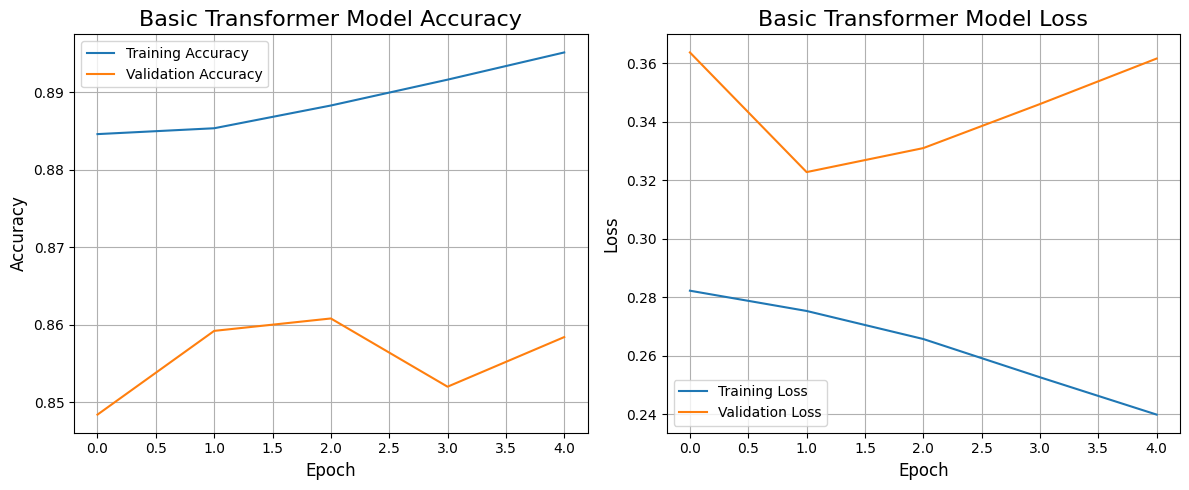

In [39]:
plot_performance(history_basic, 'Basic Transformer Model')

# 11-12. Advanced Transforrmer Model

In [ ]:
import tensorflow as tf
from keras.layers import Layer, Embedding, Dense, Dropout, GlobalAveragePooling1D, MultiHeadAttention
from keras.models import Model

class PositionalEmbedding(Layer):
    def __init__(self, maxlen, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_emb = Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

class TransformerBlock(Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = keras.Sequential([
            Dense(ff_dim, activation='relu'),
            Dense(embed_dim)
        ])
        self.layernorm1 = keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output)
        return self.layernorm2(out1 + ffn_output)

def create_advanced_transformer_model(maxlen, vocab_size, embed_dim, num_heads, ff_dim, rate):
    inputs = keras.Input(shape=(maxlen,))
    embedding_layer = PositionalEmbedding(maxlen, vocab_size, embed_dim)(inputs)
    transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim, rate)(embedding_layer)
    x = GlobalAveragePooling1D()(transformer_block)
    x = Dropout(0.5)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    
    model = Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

embed_dim_adv = 128
num_heads_adv = 8
ff_dim_adv = 256
dropout_rate_adv = 0.2

advanced_model = create_advanced_transformer_model(
    max_len, vocab_size, embed_dim_adv, num_heads_adv, ff_dim_adv, dropout_rate_adv
)

# 13. Advanced Transformer Model Training

In [43]:
history_advanced = advanced_model.fit(
    X_train,
    y_train_split,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=32
)

Epoch 1/5
485/704 ━━━━━━━━━━━━━━━━━━━━ 42s 192ms/step - accuracy: 0.6332 - loss: 0.6500

KeyboardInterrupt: 

# 14. Advanced Model Architecture and Performance

In [ ]:
advanced_model.summary()

In [ ]:
plot_performance(history_advanced, 'Advanced Transformer Model')

# 15. Model Comparison

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Evaluate Basic Model
y_pred_basic = (basic_model.predict(X_test_padded) > 0.5).astype("int32")
accuracy_basic = accuracy_score(y_test, y_pred_basic)
precision_basic = precision_score(y_test, y_pred_basic)
recall_basic = recall_score(y_test, y_pred_basic)
f1_basic = f1_score(y_test, y_pred_basic)
auc_basic = roc_auc_score(y_test, basic_model.predict(X_test_padded))

# Evaluate Advanced Model
y_pred_advanced = (advanced_model.predict(X_test_padded) > 0.5).astype("int32")
accuracy_advanced = accuracy_score(y_test, y_pred_advanced)
precision_advanced = precision_score(y_test, y_pred_advanced)
recall_advanced = recall_score(y_test, y_pred_advanced)
f1_advanced = f1_score(y_test, y_pred_advanced)
auc_advanced = roc_auc_score(y_test, advanced_model.predict(X_test_padded))

# Create a comparison DataFrame
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC-ROC'],
    'Basic Model': [accuracy_basic, precision_basic, recall_basic, f1_basic, auc_basic],
    'Advanced Model': [accuracy_advanced, precision_advanced, recall_advanced, f1_advanced, auc_advanced]
})

print(results)